### imports

In [ ]:
import requests
import pandas as pd
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt

# Models

## Basic functions used for ridge regression

In [ ]:
def train_test(df, target, test_size=0.2, random_state=None):
  df = df.sample(frac=1, random_state=random_state)
  split_index = int(len(df) * (1 - test_size))
  train_df = df.iloc[:split_index]
  test_df = df.iloc[split_index:]
  X_train = train_df.drop(target, axis=1)
  y_train = train_df[target]
  X_test = test_df.drop(target, axis=1)
  y_test = test_df[target]

  return X_train, y_train, X_test, y_test

def r_squared(y_predictions, y_test):
    y_predictions = np.array(y_predictions).ravel()
    y_test = np.array(y_test).ravel()
    return 1 - (np.sum((y_predictions - y_test)**2) / np.sum((y_test - np.mean(y_test))**2))
def drop_highly_correlated_columns(X, threshold=0.95):
    X_df = pd.DataFrame(X)  # Ensure input is a DataFrame
    corr_matrix = X_df.corr().abs()  # Compute absolute correlation matrix

    # Get the upper triangle of the correlation matrix
    upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

    # Identify columns to drop based on the threshold
    to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > threshold)]

    # Return the columns to keep
    return [col for col in X_df.columns if col not in to_drop]
def calculate_mse(y_true, y_pred):
    y_true = np.array(y_true).reshape(-1, 1)
    y_pred = np.array(y_pred).reshape(-1, 1)
    return np.mean((y_true - y_pred) ** 2)


## Ridge Regression

This has functions for

1.   Fitting and Predicting

1.   Calculating MSE and R squared to compare models

1.   Plotting Residual plots
2.   Cross validating






In [ ]:
class RidgeRegression:
    def __init__(self, alpha=1.0, correlation_threshold = .9):
        self.alpha = alpha
        self.coefficients = None
        self.column_names = None
        self.predictions = None
        self.residuals = None
        self.correlation_threshold = correlation_threshold

    def drop_highly_correlated_columns(self, X):
        X_df = pd.DataFrame(X)
        corr_matrix = X_df.corr().abs()
        upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
        to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > self.correlation_threshold)]
        return [col for col in X_df.columns if col not in to_drop]

    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            self.selected_features = self.drop_highly_correlated_columns(X)
            X = X[self.selected_features]
            self.column_names = ['Intercept'] + list(X.columns)
        X = np.array(X)
        y = np.array(y).reshape(-1, 1)

        X = np.column_stack((np.ones(X.shape[0]), X))

        n_samples, n_features = X.shape

        identity = np.eye(n_features)
        identity[0, 0] = 0

        X_T = X.T
        self.coefficients = np.linalg.inv(X_T @ X + self.alpha * identity) @ X_T @ y

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X[self.selected_features]

        X = np.array(X)
        X = np.column_stack((np.ones(X.shape[0]), X))
        self.predictions = X @ self.coefficients
        return self.predictions

    def calculate_residuals(self, y_true):
        if self.predictions is None:
            raise ValueError("You need to make predictions first using the predict method.")
        y_true = np.array(y_true).reshape(-1, 1)
        self.residuals = y_true - self.predictions
        return self.residuals

    def get_params(self):
        intercept = self.coefficients[0][0]  # First value is the intercept
        slopes = self.coefficients[1:].flatten()  # Rest are the slopes for each feature
        return intercept, slopes
    def get_column_names(self):
        return self.column_names

    def get_feature_names(self):
        return self.column_names[1:]  # All names except 'Intercept'

    def get_coefficients_with_names(self):
        return list(zip(self.column_names, self.coefficients.flatten()))

    def plot_residuals(self):
        if self.residuals is None:
            raise ValueError("You need to calculate residuals first using the calculate_residuals method.")

        plt.figure(figsize=(10, 6))
        plt.scatter(self.predictions, self.residuals, alpha=0.5)
        plt.xlabel("Predicted Values")
        plt.ylabel("Residuals")
        plt.title("Residual Plot")
        plt.axhline(y=0, color='r', linestyle='--')
        plt.show()
    def cross_validate(self, df, target, k=5, random_state=None, correlation_threshold = .95):

        df = df.sample(frac=1, random_state=random_state).reset_index(drop=True)
        fold_size = len(df) // k

        mse_scores = []
        r2_scores = []

        for i in range(k):
            start = i * fold_size
            end = (i + 1) * fold_size if i < k - 1 else len(df)

            test_df = df.iloc[start:end]
            train_df = pd.concat([df.iloc[:start], df.iloc[end:]])

            X_train = train_df.drop(target, axis=1)
            y_train = train_df[target]
            X_test = test_df.drop(target, axis=1)
            y_test = test_df[target]

            columns_to_keep = drop_highly_correlated_columns(X_train, threshold=correlation_threshold)
            X_train = X_train[columns_to_keep]
            X_test = X_test[columns_to_keep]

            self.fit(X_train, y_train)
            y_pred = self.predict(X_test)

            mse = calculate_mse(y_test, y_pred)
            r2 = r_squared(y_pred, y_test)

            mse_scores.append(mse)
            r2_scores.append(r2)

        return {
            'mse_mean': np.mean(mse_scores),
            'r2_mean': np.mean(r2_scores)
        }

# Grabbing Alcohol data from data.iowa.gov

## Group by year, month, city, county, category name

In [ ]:
# query = """SELECT
#   upper(trim(city)) AS city, upper(trim(county)) AS county, category_name,  date_extract_y(date) AS year, date_extract_m(date) AS month, sum(sale_dollars) AS total_sale_dollars,
#   sum(sale_liters) AS total_sale_liters, sum(sale_dollars) / sum(sale_liters) AS price_per_liter
# GROUP BY upper(trim(city)),upper(trim(county)), date_extract_y(date), date_extract_m(date), category_name
# ORDER BY city, county, year
# LIMIT 30000000"""

# params = {"$query": query }
# data1 = requests.get("https://data.iowa.gov/resource/m3tr-qhgy.json", params=params)


# data1 = data1.json()
# alcSales_category = pd.DataFrame(data1)
data = requests.get("https://data.iowa.gov/resource/m3tr-qhgy.json?$query=SELECT%0A%20%20%60date%60%2C%0A%20%20%60city%60%2C%0A%20%20%60county%60%2C%0A%20%20%60category_name%60%2C%0A%20%20sum(%60sale_liters%60)%20AS%20%60sum_sale_liters%60%2C%0A%20%20sum(%60sale_dollars%60)%20AS%20%60sum_sale_dollars%60%0AGROUP%20BY%20%60date%60%2C%20%60city%60%2C%20%60county%60%2C%20%60category_name%60LIMIT%2030000000")

data = data.json()
alcSales = pd.DataFrame(data)

alcSales["date"] = pd.to_datetime(alcSales["date"])
alcSales['month'] = alcSales["date"].dt.month
alcSales['year'] = alcSales["date"].dt.year
alcSales['county'] = alcSales['county'].str.strip().str.upper()
alcSales['category_name'] = alcSales['category_name'].str.strip().str.upper()

# need to extract the date seperately

In [ ]:
alcSales.head()

,date,city,county,category_name,sum_sale_liters,sum_sale_dollars,month,year
0,2022-06-10,DECORAH,WINNESHIEK,COCKTAILS/RTD,42.00,306.18,6,2022
1,2022-10-18,SERGEANT BLUFF,WOODBURY,BLENDED WHISKIES,1.12,15.75,10,2022
2,2023-03-23,SERGEANT BLUFF,WOODBURY,WHISKEY LIQUEUR,9.05,200.70,3,2023
3,2023-01-27,VAN HORNE,BENTON,FLAVORED RUM,10.50,175.44,1,2023
4,2022-08-16,MURRAY,CLARKE,IMPORTED VODKAS,9.00,204.00,8,2022


## Query used as the main IOWA Alcohol data

This grabs the Iowa data city, county, year from date, category_name, sum sale dollars, sum sale liters, and price per liter.
It is grouped by city, county, year, and category.
Shrinks the thirty million rows to two hundred thousand.





In [ ]:
url = "https://data.iowa.gov/resource/m3tr-qhgy.json"
query = """
SELECT
  upper(trim(city)) AS city, upper(trim(county)) AS county,  date_extract_y(date) AS year, category_name, sum(sale_dollars) AS total_sale_dollars,
  sum(sale_liters) AS total_sale_liters, sum(sale_dollars) / sum(sale_liters) AS price_per_liter
GROUP BY upper(trim(city)),upper(trim(county)), date_extract_y(date), category_name
ORDER BY city, county, year
LIMIT 30000000
"""


params = {"$query": query }
data = requests.get(url, params=params)

if data.status_code == 200:
    data = data.json()
    alcSales = pd.DataFrame(data)
else:
    print(f"Error: {data.status_code}")
    try:
        error_message = data.json()['message']  # Assuming JSON error response
        print(error_message)
    except (KeyError, ValueError):
        print("Could not decode error message.")

In [ ]:
alcSales = alcSales.dropna(subset=['city'])
for column in ['year', 'total_sale_dollars', 'total_sale_liters', 'price_per_liter']:
  alcSales[column] = pd.to_numeric(alcSales[column], errors='coerce')
alcSales.shape

<ipython-input-3-b85f2350ab3a>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  alcSales[column] = pd.to_numeric(alcSales[column], errors='coerce')


(211394, 7)

## Grouping all of the new categories
In order to decrease the amount of dummy variables which would be created by each different category name. Here the number of categories will be reduced to larger names.

In [ ]:
alcSales_category = alcSales.copy()
def categorize_alcohol(item):
    if 'VODKA' in item:
        return 'Vodka'
    elif 'RUM' in item:
        return 'Rum'
    elif 'WHISK' in item:
        return 'Whiskey'
    elif 'TEQUILA' in item:
        return 'Tequila'
    elif 'BRANDIES' in item or 'BRANDY' in item:
        return 'Brandy'
    elif 'SCHNAPPS' in item:
        return 'Schnapps'
    elif 'LIQUEUR' in item or 'CORDIAL' in item:
        return 'Liqueur / Cordial'
    elif 'GIN' in item:
        return 'Gin'
    elif 'BOURBON' in item:
        return 'Bourbon'
    elif 'SCOTCH' in item:
        return 'Scotch'
    else:
        return 'Miscellaneous'

In [ ]:
alcSales_category['category_name'] = alcSales_category['category_name'].astype(str)
alcSales_category['total_sale_dollars'] = pd.to_numeric(alcSales_category['total_sale_dollars'], errors='coerce')
alcSales_category['total_sale_liters'] = pd.to_numeric(alcSales_category['total_sale_liters'], errors='coerce')

In [ ]:
alcSales_category['price_per_liter'] = alcSales_category['total_sale_dollars'] / alcSales_category['total_sale_liters']
alcSales_category['category_name'] = alcSales_category['category_name'].apply(categorize_alcohol)
grouped = alcSales_category.groupby(['city', 'county', 'year','category_name'], as_index=False).agg({
    'total_sale_dollars': 'sum',
    'total_sale_liters': 'sum',
    'price_per_liter':'sum'
})
grouped['county'] = grouped['county'].str.strip().str.upper()
grouped['city'] = grouped['city'].str.strip().str.upper()

This is to create the price per liter feature as well as prepping the data to be merged with demographic data.

In [ ]:
grouped['price_per_liter'] = grouped['total_sale_dollars'] / grouped['total_sale_liters']
alcSales_category['county'] = alcSales_category['county'].str.strip().str.upper()
alcSales_category['city'] = alcSales_category['city'].str.strip().str.upper()

In [ ]:
grouped.shape

(52710, 7)

# Read in 2012-2024 DP03 ACS Iowa Economic Demographic Data

This csv is a concatenation of the 12 years of data done in the r script.

There are some columns with 20-100 rows of na dont really want to drop the columns but do not want to use a 0. These columns might be dropped anyways when checking



In [ ]:
demo = pd.read_csv("https://raw.githubusercontent.com/alexjung417/Iowa-Demographics/refs/heads/main/Iowa%20Demographics.csv")
demo['city'] = demo['city'].str.replace(' CDP', '', regex=False)

# Then, handle the 'CITY' cases
def clean_city_name(city):
    if city.endswith(' CITY CITY'):
        return city  # Remove one 'CITY' from the end
    elif city.endswith(' CITY') and not city.startswith('CITY'):
        return city[:-5]  # Remove ' CITY' from the end if it's not at the beginning
    return city

demo['city'] = demo['city'].apply(clean_city_name)
demo['city'] = demo['city'].str.replace('CITY CITY', 'CITY', regex=False)
#demo = demo[demo['city'].isin(unique_cities)]    this would be to shrink the dataset but i do not think it matters

In [ ]:
demo = demo[demo['Population 16 years and over'] != 'Population 16 years and over'] # needed because there is 11 rows that are adding na for no reason but this is how the r script created the csv

columns_to_drop = [col for col in demo.columns if col.endswith('.1') or col.endswith('.2')]
demo = demo.drop(columns=columns_to_drop)
na_counts = demo.isnull().sum()
columns_to_drop = na_counts[na_counts > 100].index    # some rows such as earnings have too many nan which would not be fair to make 0
demo = demo.drop(columns=columns_to_drop)
for col in demo.columns:
    if na_counts[col] < 10:                         # this changes columns with nan to 0 because they are rows like average walk time, those in the private sector
        demo[col] = demo[col].fillna(0)

### used to see is there is a commonality between missing values
no need to run

In [ ]:
demo2023 = demo[demo['year'] == 2022].copy()
demo2023['year'] = 2023
demo2024 = demo[demo['year'] == 2023].copy()
demo2024['year'] = 2024

demo2 = pd.concat([demo, demo2023, demo2024]).reset_index(drop=True)

# Merging alc and demo


In [ ]:
Booze = pd.merge(grouped, demo, on=['city', 'year'], how='left')

#Booze = Booze.dropna(subset=['liters per capita'])
Booze = Booze.dropna(subset=['Families'])   # there are too many rows with nan
Booze = Booze[~Booze[['Families', 'With retirement income']].isnull().all(axis=1)]


In [ ]:
Booze.shape

(42039, 64)

In [ ]:
Booze['Population 16 years and over'] = pd.to_numeric(Booze['Population 16 years and over'], errors='coerce')
Booze['liters per capita'] = pd.to_numeric(Booze['total_sale_liters'], errors='coerce') / pd.to_numeric(Booze['Population 16 years and over'], errors='coerce')
Booze = Booze[~Booze[['liters per capita']].isnull().any(axis=1)]

### renaming year in order to make the prediction easier to explain

In [ ]:
Booze['year'] = Booze['year'] - 2011
Booze.rename(columns={'year': 'years after 2011'}, inplace=True)

## making a county group by to test as a second model

In [ ]:
Booze_nocity = Booze.drop('city', axis=1)
Booze_county = Booze_nocity.groupby(['county', 'years after 2011', 'category_name'], as_index=False).sum()

## Dummying the Category Name

In [ ]:
dummies = pd.get_dummies(Booze['category_name'], dtype='int')
demo_alc = pd.concat([Booze, dummies], axis=1)
demo_alc = demo_alc.drop(['category_name'], axis=1)

# Trying Ridge Regression

## Removing uncessary features for booze1

In [ ]:
demo_alc = demo_alc.drop(['city','county',"total_sale_liters"], axis=1)
Booze1 = demo_alc.apply(pd.to_numeric, errors='coerce')
#Booze1 = Booze1.drop_duplicates()

## running on Booze1
This is the groupby city, year, county, and category name

In [ ]:
columns_to_keep = drop_highly_correlated_columns(Booze1)
booze_uncorrelated = Booze1[columns_to_keep]
booze_uncorrelated['liters per capita']

,liters per capita
0,0.014516
1,0.030242
2,0.024194
3,0.007258
4,0.198282
...,...
52688,6.829310
52689,1.043966
52690,2.370000
52691,13.437931


R-squared: 0.20436065916641288
Intercept: 0.728422027930437
years after 2011: 0.0137106317647708
total_sale_dollars: 6.563973894355658e-07
price_per_liter: -0.0011699954557935729
Population 16 years and over: -4.105834350863329e-06
Armed Forces: -0.0009365619385167588
Public transportation (excluding taxicab): -0.0001404780069840111
Walked: 0.00019659888676031844
Other means: -0.00031829008809260335
Worked at home: -7.931972121167597e-05
Agriculture, forestry, fishing and hunting, and mining: 0.0003634338248474175
Finance and insurance, and real estate and rental and leasing: -1.2513568270310386e-05
Unpaid family workers: -0.0009819385960297086
Bourbon: -0.6904145977450151
Brandy: -0.5976107852988127
Gin: -0.6298632063225029
Liqueur / Cordial: -0.4728874804275601
Miscellaneous: -0.2860524886904835
Rum: 0.346649754924932
Schnapps: -0.4057164348459697
Scotch: -0.6855237537157522
Tequila: -0.5659656519643724
Vodka: 1.6236854404816836
Whiskey: 2.3636992018526386


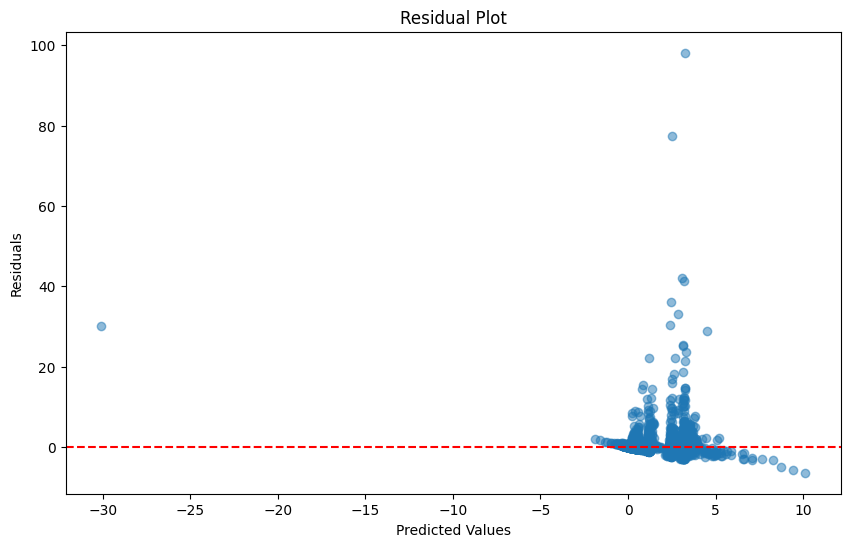

In [ ]:
X_train, y_train, X_test, y_test = train_test(Booze1, 'liters per capita')

ridge1 = RidgeRegression(alpha=.01)
ridge1.fit(X_train, y_train)

# Predict and evaluate
y_pred = ridge1.predict(X_test)
print("R-squared:", r_squared(y_pred, y_test.values))

mse = calculate_mse(y_test, y_pred)
# Get model parameters

# Now you can plot the residuals
ridge1.plot_residuals()

In [ ]:
ridge = RidgeRegression()
cv_results = ridge.cross_validate(Booze1, target='liters per capita', k=10, random_state=432)
cv_results

{'mse_mean': 3.593013779901132, 'r2_mean': 0.2772621184552687}

In [ ]:
X = demo_alc.drop('liters per capita', axis=1)
y = demo_alc['liters per capita']
ridge.fit(X, y)

In [ ]:
coefficients_with_names = ridge.get_coefficients_with_names()
print("Coefficients with names:")
for name, coef in coefficients_with_names:
    print(f"{name}: {coef}")

## Running the data on booze_county

In [ ]:
dummies = pd.get_dummies(Booze_county['category_name'], dtype='int')
county_alc = pd.concat([Booze_county, dummies], axis=1)
county_alc = county_alc.drop(['category_name'], axis=1)
county_alc = county_alc.drop(['county',"total_sale_liters"], axis=1)
county_alc = county_alc.apply(pd.to_numeric, errors='coerce')

In [ ]:
columns_to_keep = drop_highly_correlated_columns(county_alc)
booze_county_uncorrelated = county_alc[columns_to_keep]

In [ ]:
random_rows = booze_county_uncorrelated.sample(n=10)
random_rows['liters per capita']

,liters per capita
4628,0.017497
8703,1.259650
9570,2.652096
1404,4.274531
9875,0.738251
344,15.884223
7338,0.014537
43,0.548530
3712,0.282369
6134,0.590963


R-squared: 0.528467436606916
Intercept: 0.728422027930437
years after 2011: 0.0137106317647708
total_sale_dollars: 6.563973894355658e-07
price_per_liter: -0.0011699954557935729
Population 16 years and over: -4.105834350863329e-06
Armed Forces: -0.0009365619385167588
Public transportation (excluding taxicab): -0.0001404780069840111
Walked: 0.00019659888676031844
Other means: -0.00031829008809260335
Worked at home: -7.931972121167597e-05
Agriculture, forestry, fishing and hunting, and mining: 0.0003634338248474175
Finance and insurance, and real estate and rental and leasing: -1.2513568270310386e-05
Unpaid family workers: -0.0009819385960297086
Bourbon: -0.6904145977450151
Brandy: -0.5976107852988127
Gin: -0.6298632063225029
Liqueur / Cordial: -0.4728874804275601
Miscellaneous: -0.2860524886904835
Rum: 0.346649754924932
Schnapps: -0.4057164348459697
Scotch: -0.6855237537157522
Tequila: -0.5659656519643724
Vodka: 1.6236854404816836
Whiskey: 2.3636992018526386


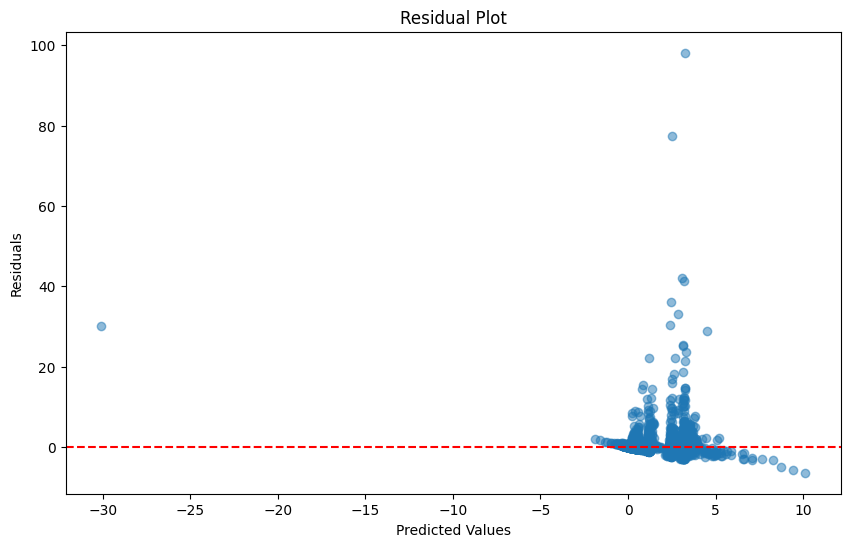

In [ ]:
X_train, y_train, X_test, y_test = train_test(county_alc, 'liters per capita')

ridge_county = RidgeRegression(alpha=.01)
ridge_county.fit(X_train, y_train)

# Predict and evaluate
y_pred = ridge_county.predict(X_test)
print("R-squared:", r_squared(y_pred, y_test.values))

mse = calculate_mse(y_test, y_pred)
# Get model parameters

ridge_county.calculate_residuals(y_test)
ridge1.plot_residuals()

## Doing Cross Validation on County model

In [ ]:
ridge_cv_county = RidgeRegression()
cv_results = ridge_cv_county.cross_validate(county_alc, target='liters per capita', k=10, random_state=9467)
cv_results

{'mse_mean': 20.351571288663827, 'r2_mean': 0.5223467001985982}

In [ ]:
X = county_alc.drop('liters per capita', axis=1)
y = county_alc['liters per capita']
ridge_cv_county.fit(X, y)

In [ ]:
coefficients_with_names = ridge_cv_county.get_coefficients_with_names()
print("Coefficients with names:")
for name, coef in coefficients_with_names:
    print(f"{name}: {coef}")

Coefficients with names:
Intercept: 1.9733267113000494
years after 2011: 0.06599223538517954
total_sale_dollars: 2.04572610143631e-06
price_per_liter: 0.0003121717894491672
Population 16 years and over: 2.369247867500364e-05
Armed Forces: -0.008802952772084328
Public transportation (excluding taxicab): -0.00015271153834658723
Other means: -0.0001519346027116858
Worked at home: -0.00025756916403001475
Unpaid family workers: 0.0020932931529508998
Bourbon: -2.522122333384124
Brandy: -2.1032449653930207
Gin: -2.1415045106398867
Liqueur / Cordial: -1.7268372946421613
Miscellaneous: -0.9526060914793475
Rum: 1.3716006250873554
Schnapps: -1.3013009786014007
Scotch: -2.5639130679344118
Tequila: -2.144330417772827
Vodka: 5.926521473152573
Whiskey: 8.15773756162014


# Graphs
That help to show the



In [ ]:
grouped_booze = Booze.groupby(['county', 'year'], as_index=False).agg({
    'Population 16 years and over': 'sum',
    'total_sale_liters': 'sum'
})

grouped_booze['liters per capita'] = grouped_booze['total_sale_liters'] / grouped_booze['Population 16 years and over']
Booze['Population 16 years and over'] = Booze['Population 16 years and over'].replace(r'[^\d.]+', '', regex=True).astype(float)
fig = px.scatter(grouped_booze, x='Population 16 years and over', y='liters per capita', color='year',
                 title='Liters per Capita by Year and City')
fig.show()

## By Sale Dollars

In [ ]:
fig = px.scatter(Booze, x='Population 16 years and over', y='total_sale_dollars', color='category_name',
                 title='Liters per Capita by Year and City')
fig.show()

## By liters per capita and county

In [ ]:
fig = px.scatter(grouped_booze, x='Population 16 years and over', y='total_sale_liters',
                 color='year',
                 title='Total Alcohol Sales vs. Population 16+ by County and Year')
fig.show()